<a href="https://colab.research.google.com/github/AlessiaSerra/Clickbait-Detection/blob/main/ClickBaitDetection_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install datasets pandas scikit-learn numpy

-Feature extraction on Train Set-
-Feature extraction on Test Set-

--------------------------------------------------
ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT
            C_d                        C_w                         U                      U_norm                    
           mean        std median     mean       std median     mean        std median      mean       std    median
label                                                                                                               
0      108.8416  14.897452  108.0  19.9472  6.015886   20.0 -88.8944  10.743622  -88.0 -1.838861  0.447098 -1.769230
1      114.2592  16.168085  112.0  27.4928  7.614062   28.0 -86.7664   9.778736  -88.0 -1.626623  0.388290 -1.543859

--------------------------------------------------

Pearson Correlation (U, Label):  0.1030 (p-value: 2.7908e-13)
Spearman Correlation (U, Label): 0.0868 (p-value: 7.8945e-10)
Two-sample t-test su U: t = 7.3240, p-value = 2.7908e-13


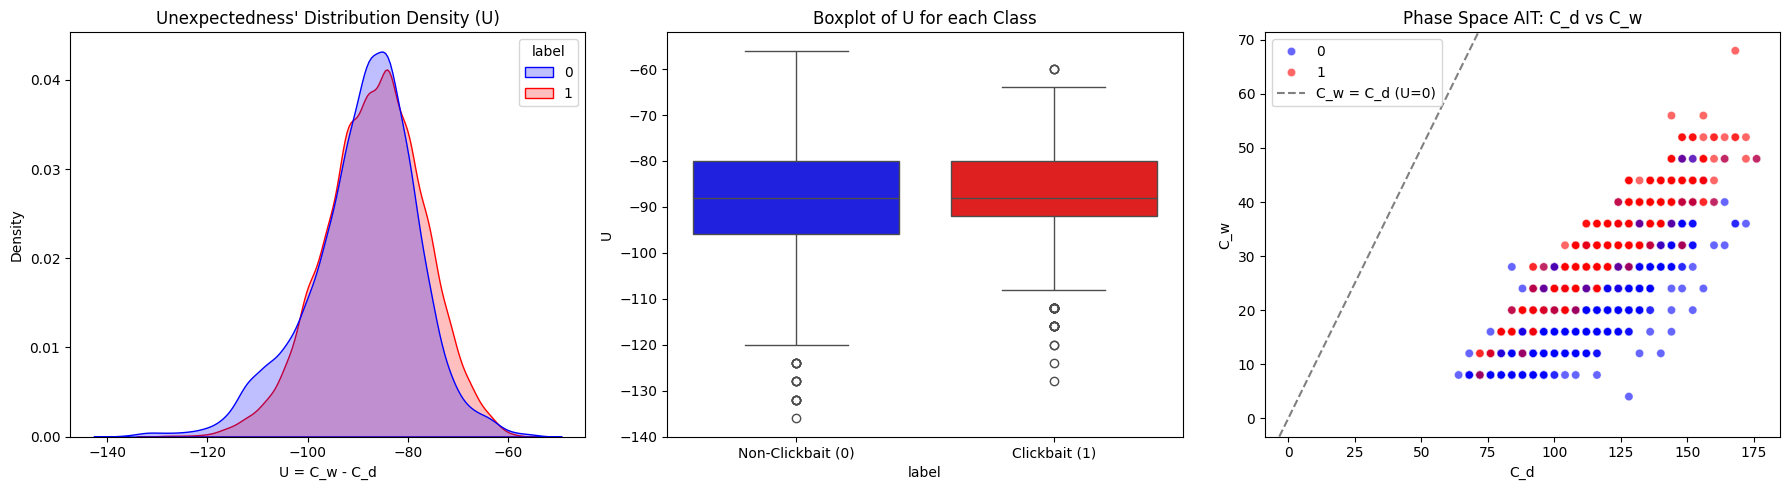


----------------------------------------------------------------------
Benchmark on Test Set
                         Model  Accuracy  F1-Score  ROC-AUC
  AIT Detector (Random Forest)    0.8073    0.8141   0.8073
            AIT Detector (KNN)    0.7593    0.7512   0.7593
Random Classifier (Stratified)    0.4953    0.4923   0.4953
  Logistic Regression (TF-IDF)    0.8887    0.8852   0.8887
   Hybrid Model (TF-IDF + AIT)    0.8987    0.8960   0.8987


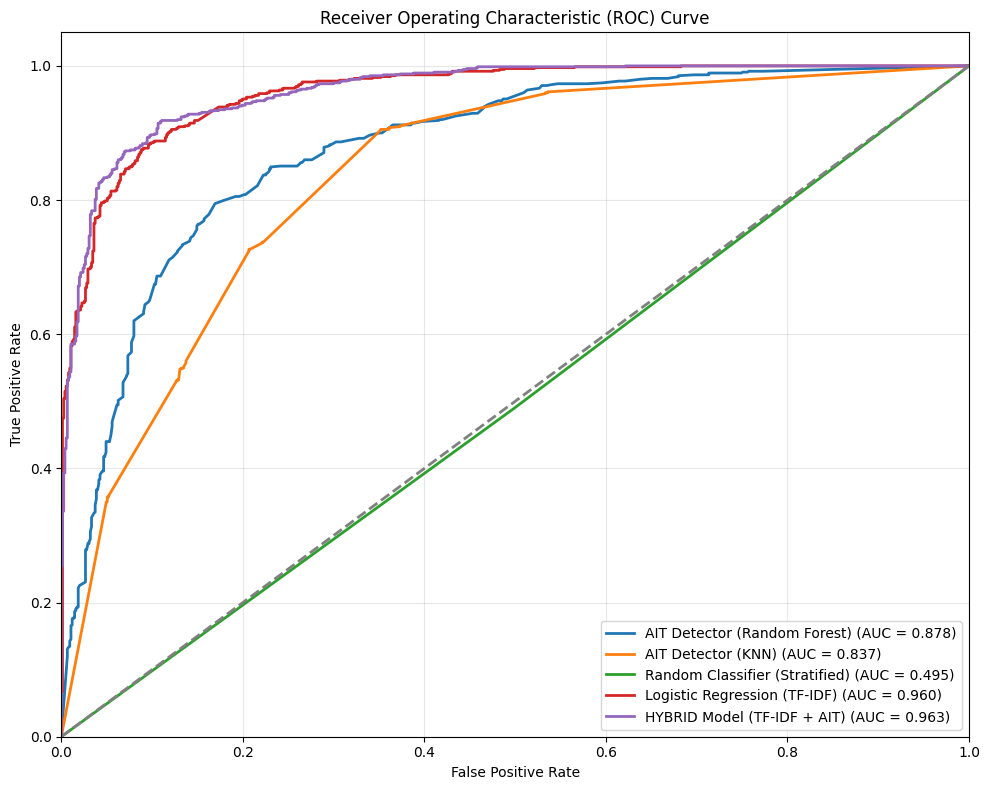

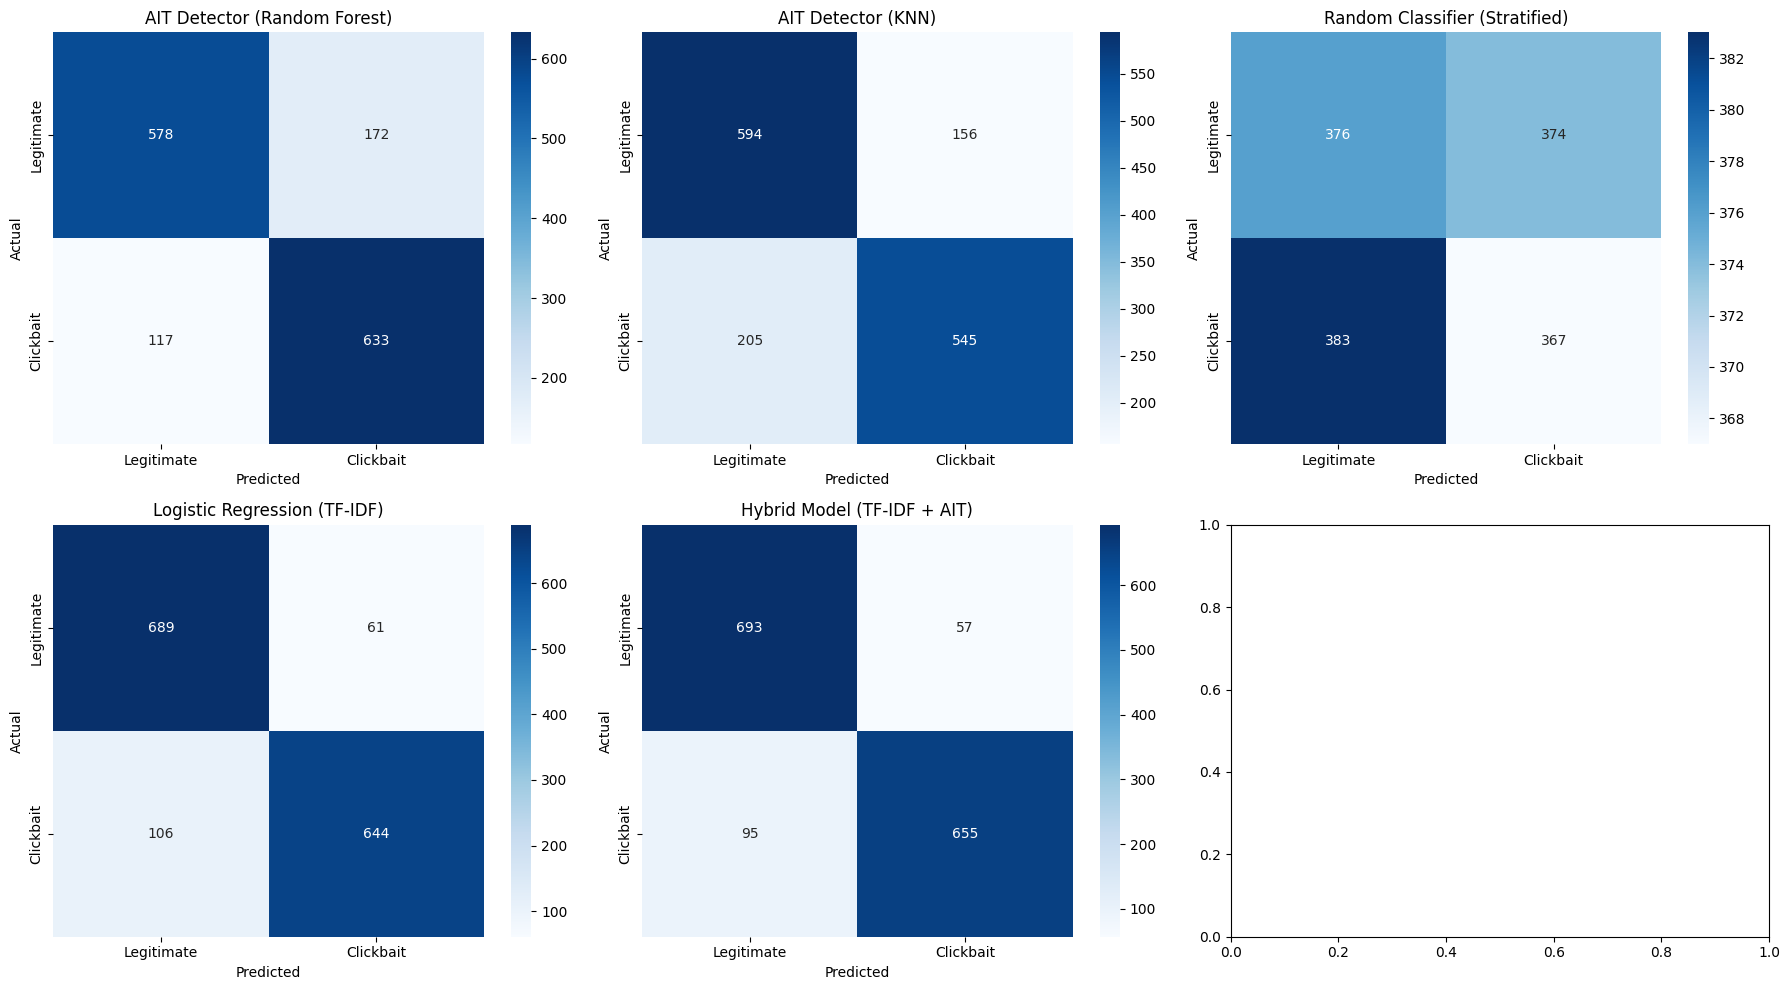

In [5]:
import lzma
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, f1_score
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.sparse import hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# Computation of Complexity and Unexpectedness
class AITComplexityEngine:
    def __init__(self, background_corpus: str):
        """
        Initializes AIT class with background corpus (World Knowledge).
        """
        self.world_knowledge = background_corpus.encode('utf-8')
        self.compressed_world_size = len(lzma.compress(self.world_knowledge))

    def get_cd(self, text: str) -> int:
        """
        Description Complexity C_d: Z(text)
        """
        return len(lzma.compress(text.encode('utf-8')))

    def get_cw(self, text: str) -> int:
        """
        Approximed Causal Complexity C_w: Z(World + text) - Z(World)
        """
        combined = self.world_knowledge + b" " + text.encode('utf-8')
        return max(len(lzma.compress(combined)) - self.compressed_world_size, 0)

    def compute_metrics(self, text: str) -> tuple:
        cd = self.get_cd(text)
        cw = self.get_cw(text)
        u = cw - cd
        u_norm = u / (len(text) + 1e-5)  #normalized to avoid bias belonging to string length
        return cd, cw, u, u_norm

#loading the dataset
raw_dataset = load_dataset("christinacdl/clickbait_detection_dataset", split="train")
df_raw = pd.DataFrame(raw_dataset)

text_col = 'text' if 'text' in df_raw.columns else ('headline' if 'headline' in df_raw.columns else df_raw.columns[0])
label_col = 'label' if 'label' in df_raw.columns else df_raw.columns[1]

sample_size = 5000
df_background = df_raw[df_raw[label_col] == 0].head(sample_size)
world_reference_text = " ".join(df_background[text_col].tolist())
engine = AITComplexityEngine(background_corpus=world_reference_text)

df_remaining = df_raw.drop(df_background.index)

df_cb = df_remaining[df_remaining[label_col] == 1].sample(sample_size // 2, random_state=42)
df_non_cb = df_remaining[df_remaining[label_col] == 0].sample(sample_size // 2, random_state=42)
df = pd.concat([df_cb, df_non_cb]).sample(frac=1.0, random_state=42).reset_index(drop=True)

train_df, test_df = train_test_split(df, test_size=0.3, random_state=42, stratify=df[label_col])

# For AIT features extraction
def extract_ait_features(dataset):
    cd_list, cw_list, u_list, unorm_list = [], [], [], []
    for text in dataset[text_col]:
        cd, cw, u, u_norm = engine.compute_metrics(str(text))
        cd_list.append(cd)
        cw_list.append(cw)
        u_list.append(u)
        unorm_list.append(u_norm)

    dataset = dataset.copy()
    dataset['C_d'] = cd_list
    dataset['C_w'] = cw_list
    dataset['U'] = u_list
    dataset['U_norm'] = unorm_list
    return dataset

print(f"-Feature extraction on Train Set-")
train_df = extract_ait_features(train_df)

print(f"-Feature extraction on Test Set-")
test_df = extract_ait_features(test_df)

#Is unexpectedness related to clickbait?
df_eda = pd.concat([train_df, test_df]).reset_index(drop=True)
print("\n" + "-"*50)
print("ANALYSIS: UNEXPECTEDNESS vs CLICKBAIT")

summary = df_eda.groupby(label_col)[['C_d', 'C_w', 'U', 'U_norm']].agg(['mean', 'std', 'median'])
print(summary.to_string())

corr_pearson, p_pearson = stats.pearsonr(df_eda['U'], df_eda[label_col])
corr_spearman, p_spearman = stats.spearmanr(df_eda['U'], df_eda[label_col])
t_stat, t_pval = stats.ttest_ind(df_eda[df_eda[label_col] == 1]['U'], df_eda[df_eda[label_col] == 0]['U'])

print("\n" + "-"*50)
print(f"\nPearson Correlation (U, Label):  {corr_pearson:.4f} (p-value: {p_pearson:.4e})")
print(f"Spearman Correlation (U, Label): {corr_spearman:.4f} (p-value: {p_spearman:.4e})")
print(f"Two-sample t-test su U: t = {t_stat:.4f}, p-value = {t_pval:.4e}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
safe_palette = {0: 'blue', 1: 'red', '0': 'blue', '1': 'red'}

# Plot for U distribution
sns.kdeplot(data=df_eda, x='U', hue=label_col, common_norm=False, fill=True, palette=safe_palette, ax=axes[0])
axes[0].set_title("Unexpectedness' Distribution Density (U)")
axes[0].set_xlabel("U = C_w - C_d")

# Boxplot U
sns.boxplot(data=df_eda, x=label_col, y='U', hue=label_col, palette=safe_palette, legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])  # Risolve il warning sui ticklabels
axes[1].set_xticklabels(["Non-Clickbait (0)", "Clickbait (1)"])
axes[1].set_title("Boxplot of U for each Class")

# Plot 3: Space C_d vs C_w
sns.scatterplot(data=df_eda, x='C_d', y='C_w', hue=label_col, alpha=0.6, palette=safe_palette, ax=axes[2])
axes[2].axline((0, 0), slope=1, color='gray', linestyle='--', label='C_w = C_d (U=0)')
axes[2].set_title("Phase Space AIT: C_d vs C_w")
axes[2].legend()

plt.tight_layout()
plt.show()


# 2. Clickbait detection
ait_features = ['C_d', 'C_w', 'U', 'U_norm']
X_train_ait = train_df[ait_features]
X_test_ait = test_df[ait_features]
y_train = train_df[label_col]
y_test = test_df[label_col]

# AIT with Random Forest
rf_ait = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_ait.fit(X_train_ait, y_train)
test_preds_rf = rf_ait.predict(X_test_ait)

# AIT with KNN
scaler_knn = StandardScaler()
X_train_ait_scaled = scaler_knn.fit_transform(X_train_ait)
X_test_ait_scaled = scaler_knn.transform(X_test_ait)

knn_ait = KNeighborsClassifier(n_neighbors=5, weights='distance')
knn_ait.fit(X_train_ait_scaled, y_train)
test_preds_knn = knn_ait.predict(X_test_ait_scaled)

# Random model
dummy_strat = DummyClassifier(strategy="stratified", random_state=42)
dummy_strat.fit(X_train_ait, y_train)
preds_strat = dummy_strat.predict(X_test_ait)

# "Classical method" (TF-IDF + Logistic Regression)
tfidf = TfidfVectorizer(max_features=3000, stop_words='english')
X_train_tfidf = tfidf.fit_transform(train_df[text_col].astype(str))
X_test_tfidf = tfidf.transform(test_df[text_col].astype(str))

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)
preds_lr = lr_model.predict(X_test_tfidf)

# Hybrid model (TF-IDF + AIT Scalato)
from sklearn.preprocessing import MaxAbsScaler
scaler_hybrid = MaxAbsScaler()
X_train_ait_hybrid = scaler_hybrid.fit_transform(X_train_ait)
X_test_ait_hybrid = scaler_hybrid.transform(X_test_ait)

X_train_hybrid = hstack([X_train_tfidf, X_train_ait_hybrid])
X_test_hybrid = hstack([X_test_tfidf, X_test_ait_hybrid])

lr_hybrid = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_hybrid.fit(X_train_hybrid, y_train)
preds_hybrid = lr_hybrid.predict(X_test_hybrid)

models = {
    "AIT Detector (Random Forest)": test_preds_rf,
    "AIT Detector (KNN)": test_preds_knn,
    "Random Classifier (Stratified)": preds_strat,
    "Logistic Regression (TF-IDF)": preds_lr,
    "Hybrid Model (TF-IDF + AIT)": preds_hybrid
}

benchmark_records = []
for name, preds in models.items():
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds)
    roc = roc_auc_score(y_test, preds)
    benchmark_records.append({
        "Model": name,
        "Accuracy": round(acc, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(roc, 4)
    })

df_benchmark = pd.DataFrame(benchmark_records)

print("\n" + "-"*70)
print("Benchmark on Test Set")
print("="*70)
print(df_benchmark.to_string(index=False))


#performance visualization
model_probs = {
    "AIT Detector (Random Forest)": rf_ait.predict_proba(X_test_ait)[:, 1],
    "AIT Detector (KNN)": knn_ait.predict_proba(X_test_ait_scaled)[:, 1],
    "Random Classifier (Stratified)": dummy_strat.predict_proba(X_test_ait)[:, 1],
    "Logistic Regression (TF-IDF)": lr_model.predict_proba(X_test_tfidf)[:, 1],
    "HYBRID Model (TF-IDF + AIT)": lr_hybrid.predict_proba(X_test_hybrid)[:, 1]
}

# ROC Curve
plt.figure(figsize=(10, 8))
for name, prob in model_probs.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f'{name} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Confusion Matrix
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, preds) in enumerate(models.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=['Legitimate', 'Clickbait'],
                yticklabels=['Legitimate', 'Clickbait'])
    axes[idx].set_title(name, fontsize=12)
    axes[idx].set_xlabel('Predicted')
    axes[idx].set_ylabel('Actual')

plt.tight_layout()
plt.show()